This file exists to outline the data quality of the datasets, outlining which issues are present.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import scipy.stats as stats
from matplotlib.ticker import FuncFormatter

from sklearn import svm

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance

from sklearn.model_selection import KFold, GroupKFold, cross_validate, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from datetime import datetime

import os
import sys

from configparser import ConfigParser
from pathlib import Path

In [3]:
# Sets the working directory so that the key files can be imported
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src" / "insurance_pricing").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)

# Make your source package importable
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from Insurance_pricing.data import Find_N_datasets, inspect_dataset, Dates_to_times, missing_length_by_age
from Insurance_pricing.cleaning import clean_types, clean_dates

In [4]:
paths = Find_N_datasets(N_files=2, path_loc='raw')
motor = pd.read_csv(paths[0], sep=";")
claims = pd.read_csv(paths[1], sep=";")

motor_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Raw\Motor.csv
claims_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Raw\Claims.csv


In [5]:
inspect_dataset(claims)

<class 'pandas.DataFrame'>
RangeIndex: 7366 entries, 0 to 7365
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   7366 non-null   int64  
 1   Cost_claims_year     7366 non-null   float64
 2   Cost_claims_by_type  7366 non-null   float64
 3   Claims_type          7366 non-null   str    
dtypes: float64(2), int64(1), str(1)
memory usage: 331.4 KB

Info of the dataset:
None

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
    

Checking the missing values:
ID                     0
Cost_claims_year       0
Cost_claims_by_type    0
Claims_type            0
dtype: int64

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
        
Stats for

In [6]:
inspect_dataset(motor)

<class 'pandas.DataFrame'>
RangeIndex: 105555 entries, 0 to 105554
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    105555 non-null  int64  
 1   Date_start_contract   105555 non-null  str    
 2   Date_last_renewal     105555 non-null  str    
 3   Date_next_renewal     105555 non-null  str    
 4   Date_birth            105555 non-null  str    
 5   Date_driving_licence  105555 non-null  str    
 6   Distribution_channel  105555 non-null  int64  
 7   Seniority             105555 non-null  int64  
 8   Policies_in_force     105555 non-null  int64  
 9   Max_policies          105555 non-null  int64  
 10  Max_products          105555 non-null  int64  
 11  Lapse                 105555 non-null  int64  
 12  Date_lapse            35147 non-null   str    
 13  Payment               105555 non-null  int64  
 14  Premium               105555 non-null  float64
 15  Cost_claims

In [7]:
motor = clean_dates(motor)

In [8]:
missing_cols = motor[['Date_lapse', 'Type_fuel', 'Length']].copy()
inspect_dataset(missing_cols)

<class 'pandas.DataFrame'>
RangeIndex: 105555 entries, 0 to 105554
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   Date_lapse  35147 non-null   datetime64[us]
 1   Type_fuel   103791 non-null  str           
 2   Length      95226 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 2.5 MB

Info of the dataset:
None

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
    

Checking the missing values:
Date_lapse    70408
Type_fuel      1764
Length        10329
dtype: int64

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
        
Stats for categorical columns:

       Type_fuel
count     103791
unique         2
top       

Data missingness has useful meaning here, it isn't erroneous.

Given that retention rates lie around [84%](https://agentblog.nationwide.com/managing-your-business-and-clients/technology/leaning-on-technology-to-increase-client-retention-in-the-insurance-industry/)

But that's not considering the fact that risk ratings are likely to jump after claims are made. This causes and increase in price and a reduced renewal chances. (about [50%](https://www.latentview.com/blog/insurance-customer-retention/))

so as long as the missnigness behaves as expected given these details. It's simply restructuring the dataset to express this would likely be enough.

| Columns             | No Claim                 | Claim Made         |
| ------------------- | ------------------------ | ------------------ | 
| Missing Date_lapse  | Expected ~84%            | Expected ~50 - 60% |
| Has Date_lapse      | Expected ~16%            | Expected ~50 - 40% |


It could be useful to check these percentages often, to give an understanding of if there's likely issues in the data.

In [9]:
# Create a copy of the motor dataset
motor_check = motor.copy()

# Get the IDs present in the claims dataset
claim_ids = claims["ID"].dropna().astype("string").str.strip()

# Check whether each motor ID appears in the claims dataset
motor_ids = motor_check["ID"].astype("string").str.strip()
motor_check["Claim_Made"] = motor_ids.isin(claim_ids)

# Create Date_lapse status
motor_check["Date_lapse_Status"] = np.where(
    motor_check["Date_lapse"].isna(),
    "Missing",
    "Recorded"
)

# Count records for each combination
counts = pd.crosstab(
    motor_check["Claim_Made"],
    motor_check["Date_lapse_Status"]
)

# Calculate percentages within each claim group
percentages = (
    counts.div(counts.sum(axis=1), axis=0) * 100
)

print("Record counts:")
print(counts)

print("\nPercentages within each claim group:")
print(percentages.round(2))

Record counts:
Date_lapse_Status  Missing  Recorded
Claim_Made                          
False                64138     30730
True                  6270      4417

Percentages within each claim group:
Date_lapse_Status  Missing  Recorded
Claim_Made                          
False                67.61     32.39
True                 58.67     41.33


In [10]:
difference = (
    counts.loc[True, "Recorded"] / counts.loc[True].sum()
    -
    counts.loc[False, "Recorded"] / counts.loc[False].sum()
) * 100

print(f"The data shows a change of about {float(round(difference, 2))} between the lapses for the the claims and none-claimed entries.")

The data shows a change of about 8.94 between the lapses for the the claims and none-claimed entries.


Due to probabilities behaving as exprected, it's acceptable to leave the missingness as it holds value.

In [11]:
claim_ids = claims["ID"].dropna().unique()

# 1 means there's a recorded termination date, 0 means no such date exists
motor_check["Contract_Terminated"] = (
    motor_check["Date_lapse"].notna().astype(int)
)

In [12]:
analysis = clean_types(clean_dates(motor_check.copy()))

for col in missing_cols:
    analysis[f"{col}_missing"] = analysis[col].isna().astype(int) # Adds missingness indicator

c:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\src\Insurance_pricing\cleaning.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(


In [13]:
analysis.columns

Index(['ID', 'Date_start_contract', 'Date_last_renewal', 'Date_next_renewal',
       'Date_birth', 'Date_driving_licence', 'Distribution_channel',
       'Seniority', 'Policies_in_force', 'Max_policies', 'Max_products',
       'Lapse', 'Date_lapse', 'Payment', 'Premium', 'Cost_claims_year',
       'N_claims_year', 'N_claims_history', 'R_Claims_history', 'Type_risk',
       'Area', 'Second_driver', 'Year_matriculation', 'Power',
       'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Type_fuel', 'Length',
       'Weight', 'Claim_Made', 'Date_lapse_Status', 'Contract_Terminated',
       'Date_lapse_missing', 'Type_fuel_missing', 'Length_missing'],
      dtype='str')

In [14]:
date_results = Dates_to_times([
    analysis["Date_start_contract"],
    analysis["Date_driving_licence"],
    analysis["Date_birth"],
    analysis["Date_lapse"],
    analysis["Date_last_renewal"],
    analysis["Date_next_renewal"]
])

columns = [
    "Policy_Age",
    "Licence_Age",
    "Policy_Maker_Age",
    "Lapse_Age",
    "Time_from_renewal"
]

for col, values in zip(columns, date_results[:5]):
    analysis[col] = values

analysis["Time_till_renewal"] = -date_results[5]

analysis["Renewed_period"] = Dates_to_times(
    [
        analysis["Date_last_renewal"],
        analysis["Date_next_renewal"]
    ],
    duration=True
)

# Curating useful classification columns
analysis['Old_Policy'] = (
    analysis["Policy_Age"] >
    (analysis["Policy_Age"].median() + analysis["Policy_Age"].std())
).astype(int)

analysis['Young_Policy'] = (
    analysis["Policy_Age"] <
    abs(analysis["Policy_Age"].median() - analysis["Policy_Age"].std())
).astype(int)

analysis['Old_Policy_Maker'] = (
    analysis["Policy_Maker_Age"] >
    (analysis["Policy_Maker_Age"].median() + analysis["Policy_Maker_Age"].std())
).astype(int)

analysis['Young_Policy_Maker'] = (
    analysis["Policy_Maker_Age"] <
    abs(analysis["Policy_Maker_Age"].median() - analysis["Policy_Maker_Age"].std())
).astype(int)

analysis['Heavy_Vehical'] = (
    analysis["Weight"] >
    (analysis["Weight"].median() + analysis["Weight"].std())
).astype(int)

analysis['Light_Vehical'] = (
    analysis["Weight"] <
    abs(analysis["Weight"].median() - analysis["Weight"].std())
).astype(int)

In [15]:
Curated_dist_markers = analysis.copy()[[
                        'Old_Policy', 'Old_Policy_Maker', 'Heavy_Vehical',
                        'Young_Policy','Young_Policy_Maker', 'Light_Vehical',
                        'Contract_Terminated'
                         ]]

# we need a better way to access the paths as the numbered indicies can be easy to forget to change
save_path = Find_N_datasets(2, 'curated')[1]

save_path.parent.mkdir(parents=True, exist_ok=True)

table = pa.Table.from_pandas(
    Curated_dist_markers,
    preserve_index=False
)

pq.write_table(table, save_path)
check = pd.read_parquet(save_path)

print(check.shape)
print(check.head())

imputed_lengths: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Curated\Length_Imputation_Comparison.parquet
distribution_based_categories: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Curated\Distribution_Categories.parquet
(105555, 7)
   Old_Policy  Old_Policy_Maker  Heavy_Vehical  Young_Policy  \
0           0                 1              0             0   
1           0                 1              0             0   
2           0                 1              0             0   
3           0                 1              0             0   
4           0                 1              0             0   

   Young_Policy_Maker  Light_Vehical  Contract_Terminated  
0                   0              1                    0  
1                   0              1                    0  
2                   0              1                    0  
3                   0              1          

In [16]:
Length_imputation = analysis[
    [  
        'ID', 'Distribution_channel', 'Seniority', 'Policies_in_force', 
        'Max_policies', 'Max_products', 'Lapse', 'Date_lapse',
        'Payment', 'Premium', 'Cost_claims_year', 'N_claims_year',
        'N_claims_history', 'R_Claims_history', 'Type_risk', 'Area',
        'Second_driver', 'Year_matriculation', 'Power', 'Cylinder_capacity',
        'Value_vehicle', 'N_doors', 'Type_fuel', 'Length', 'Weight', 'Date_lapse_missing',
       'Type_fuel_missing', 'Length_missing', 'Policy_Age', 'Licence_Age',
       'Policy_Maker_Age', 'Lapse_Age', 'Time_from_renewal', 'Time_till_renewal', 'Renewed_period',
        'Old_Policy', 'Old_Policy_Maker', 'Heavy_Vehical', 'Young_Policy','Young_Policy_Maker',
        'Light_Vehical', 'Contract_Terminated'
    ]
].copy()
#Length_imputation.dropna(subset=["Length","Type_fuel"], inplace=True)
Length_imputation.head()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Date_lapse,Payment,Premium,...,Time_from_renewal,Time_till_renewal,Renewed_period,Old_Policy,Old_Policy_Maker,Heavy_Vehical,Young_Policy,Young_Policy_Maker,Light_Vehical,Contract_Terminated
0,1,0,4,1,2,1,0,NaT,0,222.52,...,11.006160,-10.004107,1.002053,0,1,0,0,0,1,0
1,1,0,4,1,2,1,0,NaT,0,213.78,...,10.004107,-9.004791,0.999316,0,1,0,0,0,1,0
2,1,0,4,2,2,1,0,NaT,0,214.84,...,9.004791,-8.005476,0.999316,0,1,0,0,0,1,0
3,1,0,4,2,2,1,0,NaT,0,216.99,...,8.005476,-7.006160,0.999316,0,1,0,0,0,1,0
4,2,0,4,2,2,1,0,NaT,1,213.70,...,9.114305,-8.114990,0.999316,0,1,0,0,0,1,0


In [17]:
Length_imputation.keys()

Index(['ID', 'Distribution_channel', 'Seniority', 'Policies_in_force',
       'Max_policies', 'Max_products', 'Lapse', 'Date_lapse', 'Payment',
       'Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history',
       'R_Claims_history', 'Type_risk', 'Area', 'Second_driver',
       'Year_matriculation', 'Power', 'Cylinder_capacity', 'Value_vehicle',
       'N_doors', 'Type_fuel', 'Length', 'Weight', 'Date_lapse_missing',
       'Type_fuel_missing', 'Length_missing', 'Policy_Age', 'Licence_Age',
       'Policy_Maker_Age', 'Lapse_Age', 'Time_from_renewal',
       'Time_till_renewal', 'Renewed_period', 'Old_Policy', 'Old_Policy_Maker',
       'Heavy_Vehical', 'Young_Policy', 'Young_Policy_Maker', 'Light_Vehical',
       'Contract_Terminated'],
      dtype='str')

In [18]:
cols = [
    'Type_risk',
    'Type_fuel', 
    'Date_lapse_missing',
    'Payment',
    'Second_driver',
    'Distribution_channel',
    'Area',
    'Old_Policy',
    'Old_Policy_Maker',
    'Heavy_Vehical',
    'Light_Vehical',
    'Young_Policy',
    'Young_Policy_Maker',
    'Contract_Terminated'
]

temp = []
acceptance = 0.05

for col in cols:
    print(f"\n{col}\n")
    table = pd.crosstab(
        Length_imputation['Length_missing'],
        Length_imputation[col]
    )
    print(f"{table}\n")
    chi2, p, dof, ex = stats.chi2_contingency(table,)
    print(f"p-value: {p}") 
    if p <= acceptance:
        temp.append(col)


Type_risk

Type_risk          1      2      3    4
Length_missing                         
0                  2  12954  82247   23
1               8500    258    743  828

p-value: 0.0

Type_fuel

Type_fuel         0.0    1.0
Length_missing              
0               63600  31626
1                1398   7167

p-value: 0.0

Date_lapse_missing

Date_lapse_missing      0      1
Length_missing                  
0                   31818  63408
1                    3329   7000

p-value: 0.015815026517028367

Payment

Payment             0      1
Length_missing              
0               62146  33080
1                9718    611

p-value: 0.0

Second_driver

Second_driver       0      1
Length_missing              
0               82250  12976
1               10247     82

p-value: 1.598025688136845e-309

Distribution_channel

Distribution_channel      0      1
Length_missing                    
0                     51546  43680
1                      6371   3958

p-value: 1.64474459

Given these values, MAR is most likely the case and MCAR analysis seems to not be useful here. This is as the p values are so exceptionally small. We should likely investigate how the relationship be behaves, looking at proportions of missingness across different groups and how it develops with age through plots.

In addition we will fit the data with an equation to show that MCAR isn't the case.

In [19]:
groups = ['Type_risk','Date_lapse_missing', 'N_doors', 'Second_driver','Old_Policy']
group_of_interest = groups[0]
group_filter = 1
Length_imputation[group_of_interest].unique()

array([1, 3, 2, 4])

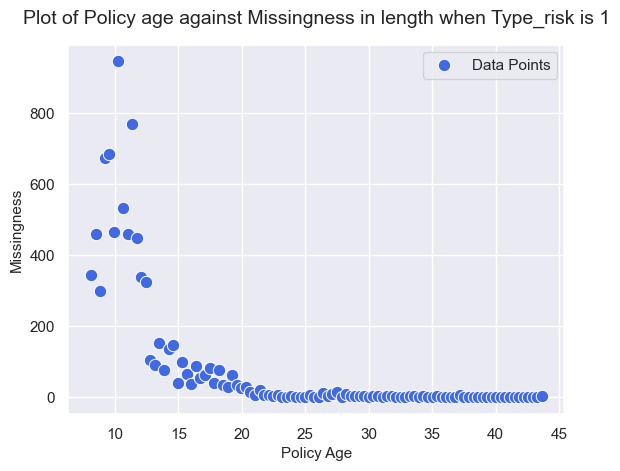

In [20]:
x1, y1, x2, y2 = missing_length_by_age(Length_imputation, age_col='Policy_Age', n_bins=100, condition = (Length_imputation[group_of_interest] == group_filter))
df_plotting = pd.DataFrame({
    "x": x1,
    "y": y1
})

sns.set_theme(style="darkgrid")

sns.scatterplot(data=df_plotting, x='x', y='y', color='royalblue', s=80, label='Data Points')


plt.title(f'Plot of Policy age against Missingness in length when {group_of_interest} is {group_filter}', fontsize=14, pad=15)
plt.xlabel('Policy Age', fontsize=11)
plt.ylabel('Missingness', fontsize=11)

plt.show()

We see this behaviour in the majority cases for group filters. This suggests that the missingness is likely an issue to be resolved in the dataset rather than a "feature". With Length values being added as the policy persists.

Due to this, ML for data imputation can be seen as a reasonable solution to this issue.

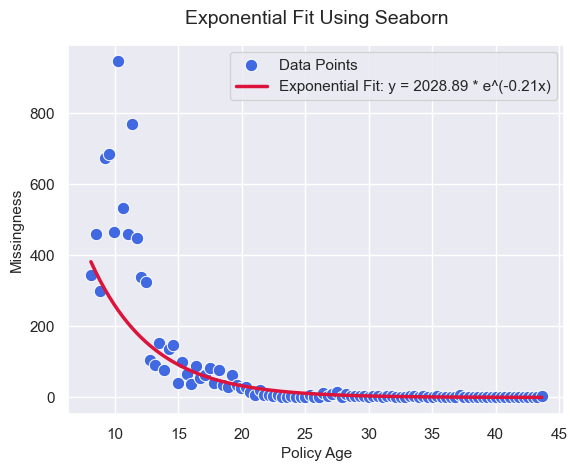

In [21]:
mask = (
    (df_plotting['y'] > 0) &
    np.isfinite(df_plotting['x']) &
    np.isfinite(df_plotting['y'])
)

x = df_plotting.loc[mask, 'x']
log_y = np.log(df_plotting.loc[mask, 'y'])

m, c = np.polyfit(x, log_y, 1)

a = np.exp(c)

x_smooth = np.linspace(df_plotting['x'].min(), df_plotting['x'].max(), 100)
y_pred = a * np.exp(m * x_smooth)

sns.set_theme(style="darkgrid")

sns.scatterplot(data=df_plotting, x='x', y='y', color='royalblue', s=80, label='Data Points')

sns.lineplot(x=x_smooth, y=y_pred, color='crimson', linewidth=2.5, 
             label=f'Exponential Fit: y = {a:.2f} * e^({m:.2f}x)')

plt.title('Exponential Fit Using Seaborn', fontsize=14, pad=15)
plt.xlabel('Policy Age', fontsize=11)
plt.ylabel('Missingness', fontsize=11)

plt.show()


In [22]:
print(temp)
temp_2 = temp.copy()
for item in temp_2:
    if len(Length_imputation[item].unique()) == 2:
        temp.remove(item)
print(temp)

['Type_risk', 'Type_fuel', 'Date_lapse_missing', 'Payment', 'Second_driver', 'Distribution_channel', 'Area', 'Old_Policy', 'Old_Policy_Maker', 'Light_Vehical', 'Young_Policy_Maker', 'Contract_Terminated']
['Type_risk', 'Type_fuel']


Now to fix the issues associated with the missingness seen in the type fuel.

In [23]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

encoded = encoder.fit_transform(Length_imputation[temp])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(temp),
    index=Length_imputation.index
)

Length_imputation = pd.concat([Length_imputation, encoded_df], axis=1)
Length_imputation.drop(columns=temp, inplace=True)
Length_imputation.rename(columns={"Type_risk_1":"Is_Motorbike",
                                  "Type_risk_2":"Is_Van",
                                  "Type_risk_3":"Is_Passenger_Car",
                                  "Type_risk_4":"Is_Agricultural",

                                  "Type_fuel_0.0" : "Fuel_Petrol",
                                  "Type_fuel_1.0" :	"Fuel_Diesel",
                                  "Type_fuel_missing": "Fuel_Unknown"},inplace=True)
Length_imputation.head()

C:\Users\alloh\AppData\Local\Temp\ipykernel_6432\1270507922.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  Length_imputation.drop(columns=temp, inplace=True)
C:\Users\alloh\AppData\Local\Temp\ipykernel_6432\1270507922.py:13: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  Length_imputation.rename(columns={"Type_risk_1":"Is_Motorbike",


,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Date_lapse,Payment,Premium,...,Young_Policy_Maker,Light_Vehical,Contract_Terminated,Is_Motorbike,Is_Van,Is_Passenger_Car,Is_Agricultural,Fuel_Petrol,Fuel_Diesel,Type_fuel_nan
0,1,0,4,1,2,1,0,NaT,0,222.52,...,0,1,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,0,4,1,2,1,0,NaT,0,213.78,...,0,1,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1,0,4,2,2,1,0,NaT,0,214.84,...,0,1,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,0,4,2,2,1,0,NaT,0,216.99,...,0,1,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,2,0,4,2,2,1,0,NaT,1,213.70,...,0,1,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
# Define the target and predictor columns
target = "Length"

numerical_cols = [
    'Seniority', 'Policies_in_force',
    'Max_policies', 'Max_products', 'Lapse',
    'Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history',
    'R_Claims_history', 'Year_matriculation',
    'Power', 'Cylinder_capacity', 'Value_vehicle', 'N_doors',
    'Weight', 'Date_lapse_missing',
    'Policy_Age', 'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age',
    'Time_from_renewal', 'Time_till_renewal', 'Renewed_period',
]

categorical_cols = [
    'Old_Policy', 'Distribution_channel', 'Payment', 'Second_driver',
    'Old_Policy_Maker','Heavy_Vehical', 'Is_Motorbike', 'Is_Van',
    'Is_Passenger_Car', 'Area', 'Is_Agricultural', 'Fuel_Petrol',
    'Fuel_Diesel', 'Fuel_Unknown'
]

features = numerical_cols + categorical_cols

# Separate observations with known and missing Length
known = Length_imputation.loc[
    Length_imputation[target].notna()
].copy()

missing = Length_imputation.loc[
    Length_imputation[target].isna()
].copy()

X = known[features]
y = known[target]

Learning_curve = []

# Define the target and predictors
target = "Length"

# Keep rows where Length is known
known = Length_imputation.dropna(subset=[target]).copy()

X = known[features]
y = known[target]

"""cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)"""

cv = GroupKFold(
    n_splits=5
)

scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }

# Predict missing Length values
missing_mask = Length_imputation["Length"].isna()
N_jobs = os.cpu_count()-4

params = {
    "cv": GroupKFold(n_splits=5),
    "scoring": scoring,
    "N_jobs": (os.cpu_count()-4), # Ignore the red here it's wrong.
    "groups": known["ID"]
    }

In [27]:
baseline_results = []
groups = known["ID"]


for strategy in ["mean", "median"]:

    baseline = DummyRegressor(strategy=strategy)

    scores = cross_validate(
        baseline,
        X,
        y,
        cv=cv,
        groups = groups,
        scoring=scoring
    )

    
    print(f"Method: {strategy.capitalize()}")
    print(f"MAE: {-scores['test_MAE'].mean()}")
    print(f"MAE_std: {scores['test_MAE'].std()}")
    print(f"RMSE: {-scores['test_RMSE'].mean()}")
    print(f"RMSE_std: {scores['test_RMSE'].std()}")
    print(f"R2: {-scores['test_R2'].mean()}")
    print(f"R2_std: {scores['test_R2'].std()}")

    # Fit on all known Length observations
    baseline.fit(X, y)

    # Preserve the original Length column
    Length_imputation["Length_baseline"] = Length_imputation["Length"]

    # Predict missing Length values
    missing_mask = Length_imputation["Length"].isna()

    Length_imputation.loc[missing_mask, "Length_baseline"] = baseline.predict(
        Length_imputation.loc[missing_mask, features]
    )

Method: Mean
MAE: 0.2829607414276617
MAE_std: 0.004790809072984298
RMSE: 0.39314412436488666
RMSE_std: 0.00882112297506402
R2: 0.00035988878940016453
R2_std: 0.00020021179695569615
Method: Median
MAE: 0.28265324365072997
MAE_std: 0.004884848455952381
RMSE: 0.3936696018861193
RMSE_std: 0.008885713600718895
R2: 0.003031396251816654
R2_std: 0.0020801005810211935


In [31]:
rfr = Pipeline([
            (("imputer", SimpleImputer(strategy="median"))),
            ("model", RandomForestRegressor(n_estimators=200,
            random_state=42,
            n_jobs= N_jobs, # Based on the num of cores
            max_depth = 3
            ))
        ])


cv_results_rfr = cross_validate(
    rfr,
    X,
    y,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    groups=groups,
    return_train_score= True,
    n_jobs=N_jobs
)


# Convert negative scores into positive errors
mae_scores = -cv_results_rfr["test_MAE"]
rmse_scores = -cv_results_rfr["test_RMSE"]
R2_scores = cv_results_rfr["test_R2"]

print(f"Mean MAE: {mae_scores.mean():.4f}")
print(f"MAE standard deviation: {mae_scores.std():.4f}")

print(f"Mean R^2:  {R2_scores.mean():.4f}")
print(f"R^2 standard deviation: {R2_scores.std():.4f}")

print(f"Mean RMSE: {rmse_scores.mean():.4f}")
print(f"RMSE standard deviation: {rmse_scores.std():.4f}")

# Fit on all known Length observations
rfr.fit(X, y)

# Preserve the original Length column
Length_imputation["Length_RFR"] = Length_imputation["Length"]

Length_imputation.loc[missing_mask, "Length_RFR"] = rfr.predict(
    Length_imputation.loc[missing_mask, features]
)

Mean MAE: 0.1426
MAE standard deviation: 0.0013
Mean R^2:  0.7253
R^2 standard deviation: 0.0026
Mean RMSE: 0.2060
RMSE standard deviation: 0.0050


In [37]:
gbr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.1,
        loss="absolute_error", # We want absolute error to avoid the impace the squared_error has on GBR
        max_depth=3,
        random_state=42
    ))
])

# parameter options for the tunning
param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_leaf": [1, 3, 5]
}

gbr_search = RandomizedSearchCV(
    estimator=gbr,
    param_distributions=param_distributions,
    n_iter=20,
    scoring=scoring,
    refit= 'MAE',
    cv=cv,
    #groups=groups,
    n_jobs=N_jobs,
    random_state=42,
    verbose=2
)


# Fit on all known Length observations
gbr_search.fit(X, y,groups=groups)

print(gbr_search.best_params_)
print(-gbr_search.best_score_)

gbr_best = gbr_search.best_estimator_

results = gbr_search.cv_results_
best_idx = gbr_search.best_index_

# Validation scores
mae = -results["mean_test_MAE"][best_idx]
mae_std = results["std_test_MAE"][best_idx]

r2 = results["mean_test_R2"][best_idx]
r2_std = results["std_test_R2"][best_idx]

rmse = -results["mean_test_RMSE"][best_idx]
rmse_std = results["std_test_RMSE"][best_idx]

print(f"Mean MAE: {mae:.4f}")
print(f"MAE standard deviation: {mae_std:.4f}")

print(f"Mean R^2:  {r2:.4f}")
print(f"R^2 standard deviation: {r2_std:.4f}")

print(f"Mean RMSE: {rmse:.4f}")
print(f"RMSE standard deviation: {rmse_std:.4f}")

# Preserve the original Length column
Length_imputation["Length_GBR"] = Length_imputation["Length"]

Length_imputation.loc[missing_mask, "Length_GBR"] = gbr_best.predict(
    Length_imputation.loc[missing_mask, features]
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
{'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_depth': 4, 'model__learning_rate': 0.1}
0.09436051325201637
Mean MAE: 0.0944
MAE standard deviation: 0.0020
Mean R^2:  0.8410
R^2 standard deviation: 0.0073
Mean RMSE: 0.1568
RMSE standard deviation: 0.0068


These results suggest that the RFR is very effective for imputing the lengths data. While the GBR lags behind. This is due to GBR requiring tunning of parameters for effective usage.

In [38]:
Length_imputation["Length_Mean"] = Length_imputation['Length'].fillna(Length_imputation['Length'].mean())
Length_imputation["Length_Median"] = Length_imputation['Length'].fillna(Length_imputation['Length'].median())
Length_imputation[['Length','Length_Mean', 'Length_RFR','Length_GBR',"Length_Median"]]

,Length,Length_Mean,Length_RFR,Length_GBR,Length_Median
0,NaN,4.252007,3.645232,2.869588,4.230
1,NaN,4.252007,3.645232,2.869588,4.230
2,NaN,4.252007,3.645232,2.859079,4.230
3,NaN,4.252007,3.645232,2.859079,4.230
4,NaN,4.252007,3.645232,2.859079,4.230
...,...,...,...,...,...
105550,4.740,4.740000,4.740000,4.740000,4.740
105551,4.650,4.650000,4.650000,4.650000,4.650
105552,3.495,3.495000,3.495000,3.495000,3.495
105553,4.555,4.555000,4.555000,4.555000,4.555


Given the overall Metrics produced by all these methods, it's clear that the RFR is the best option as it has the best metrics. Now we may move onto tasks outside of data imputation!

We will then produce a dataset using our findings and from this, databases may be created that can be used for the data analysis and predictive modelling more effectively

In [39]:
Length_copy = Length_imputation.copy()


Length_copy.loc[missing_mask, "Length"] = (
    Length_copy.loc[missing_mask, "Length_GBR"]
)

Length_imputation['Length'] = Length_copy['Length']

In [41]:
Curated_Lengths = Length_copy[['Length_missing','Length_baseline','Length_GBR',
                     'Length_RFR', 'Length_Mean',
                     'Length_Median']].copy()

save_path = Find_N_datasets(1, 'curated')[0]
print(save_path)

save_path.parent.mkdir(parents=True, exist_ok=True)

table = pa.Table.from_pandas(
    Curated_Lengths,
    preserve_index=False
)

pq.write_table(table, save_path)

imputed_lengths: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Curated\Length_Imputation_Comparison.parquet
C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Curated\Length_Imputation_Comparison.parquet


In [46]:
finish = Length_imputation.copy()
finish['Contract_Terminated'] = motor_check["Contract_Terminated"]
finish['Heavy_vehicle'] = finish['Heavy_Vehical']
finish['Light_Vehical'] = finish['Light_Vehical']
finish.columns

Index(['ID', 'Distribution_channel', 'Seniority', 'Policies_in_force',
       'Max_policies', 'Max_products', 'Lapse', 'Date_lapse', 'Payment',
       'Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history',
       'R_Claims_history', 'Area', 'Second_driver', 'Year_matriculation',
       'Power', 'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Length',
       'Weight', 'Date_lapse_missing', 'Fuel_Unknown', 'Length_missing',
       'Policy_Age', 'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age',
       'Time_from_renewal', 'Time_till_renewal', 'Renewed_period',
       'Old_Policy', 'Old_Policy_Maker', 'Heavy_Vehical', 'Young_Policy',
       'Young_Policy_Maker', 'Light_Vehical', 'Contract_Terminated',
       'Is_Motorbike', 'Is_Van', 'Is_Passenger_Car', 'Is_Agricultural',
       'Fuel_Petrol', 'Fuel_Diesel', 'Type_fuel_nan', 'Length_baseline',
       'Length_RFR', 'Length_GBR', 'Length_Mean', 'Length_Median',
       'Heavy_vehicle'],
      dtype='str')

In [47]:
finish.drop(columns=['Length_baseline','Length_GBR',
                     'Length_RFR', 'Length_Mean',
                     'Length_Median','Heavy_Vehical', 'Light_Vehical'], inplace = True)

C:\Users\alloh\AppData\Local\Temp\ipykernel_6432\1437464974.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  finish.drop(columns=['Length_baseline','Length_GBR',


In [48]:
finish.columns

Index(['ID', 'Distribution_channel', 'Seniority', 'Policies_in_force',
       'Max_policies', 'Max_products', 'Lapse', 'Date_lapse', 'Payment',
       'Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history',
       'R_Claims_history', 'Area', 'Second_driver', 'Year_matriculation',
       'Power', 'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Length',
       'Weight', 'Date_lapse_missing', 'Fuel_Unknown', 'Length_missing',
       'Policy_Age', 'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age',
       'Time_from_renewal', 'Time_till_renewal', 'Renewed_period',
       'Old_Policy', 'Old_Policy_Maker', 'Young_Policy', 'Young_Policy_Maker',
       'Contract_Terminated', 'Is_Motorbike', 'Is_Van', 'Is_Passenger_Car',
       'Is_Agricultural', 'Fuel_Petrol', 'Fuel_Diesel', 'Type_fuel_nan',
       'Heavy_vehicle'],
      dtype='str')

In [51]:
paths = Find_N_datasets(N_files=2, path_loc='processed')

motor_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Processed\Motor_Clean.csv
claims_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Processed\Claims_Clean.csv


In [50]:
finish.to_csv(
    paths[0],
    index=False,
    sep=";"
)

claims.to_csv(
    paths[1],
    index=False,
    sep=";"
)